In [1]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
df_train = trizod_df[~trizod_df["is_test"]]
# df_test = trizod_df[trizod_df["is_test"]]

In [3]:
filename = "train.csv"
# !adopt2g-catboost predict --in train.fasta --out train.csv

if not os.path.exists(filename):
    fasta_filename = "train.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_train.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "adopt2g-predict",
            "--input",
            fasta_filename,
            "--out",
            filename,
            # "--no",  # "--save"
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.array(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

,sequence,mean_gscore,mean_gscore_lower,mean_gscore_upper,gscores,gscores_lower,gscores_upper
label,,,,,,,
9_1_1_1,XQHADPICNKPCKTHDDCSGAWFCQACWNSARTCGPYVG,0.115948,0.083021,0.159660,"[nan, 0.38676344637927973, 0.43014734858584286...","[nan, 0.19284318455981606, 0.17823957704961693...","[nan, 0.6248659941341522, 0.7242856140011491, ..."
26_1_1_1,MADPNRFRGKDLPVLDQLTDPP,0.680943,0.155455,0.961159,"[0.5003459453030736, 0.612077822066995, 0.5314...","[0.08494710334281272, 0.16251290542519845, 0.1...","[0.915356041864219, 0.9276259821794456, 0.8615..."
32_1_1_1,MKPVTLYDVAEYAGVSYQTVSRVVNQASHVSAKTREKVEAAMAELN...,0.126866,0.049903,0.286708,"[0.4877725189700858, 0.29992474357634236, 0.24...","[0.21239534653504916, 0.18742996146324947, 0.1...","[0.7708100121686987, 0.4431184054407691, 0.412..."
41_1_1_1,VFCTCRGFLCGSGERASGSCTINGVRHTLCCRR,0.084559,0.010826,0.438070,"[0.2040245319606754, 0.08882029240011773, 0.07...","[0.042087727915618836, 0.012527931992744799, 0...","[0.5994851388242115, 0.42871168674230137, 0.29..."
58_1_1_1,AKTIKITQTXSAIGRLXXHKATLLGLGLRRIGHTVEREDTXAIRGM...,0.112576,0.038818,0.284933,"[0.23300752342477682, 0.14915918827525723, 0.0...","[0.06052939020253899, 0.04716186703417665, 0.0...","[0.588889130767832, 0.3830641686805551, 0.2208..."
...,...,...,...,...,...,...,...
53400_1_1_1,KCGSLGNIHHKPGGGQVEVKSEKLDFKDRVQSKIGSLDNITHVPGG...,0.844881,0.725096,0.918350,"[0.7545534430129951, 0.8608377620505786, 0.801...","[0.49877929930031345, 0.6462369886453169, 0.59...","[0.9046505351008906, 0.954477994846878, 0.9167..."
53421_1_1_1,MSGSHHHHHHSSGIEGRGRENLYFQGQVQLVESGGGVVQPGRSLRL...,0.108659,0.072150,0.160448,"[0.36285631143426317, 0.5855752115734776, 0.65...","[0.2681740995451041, 0.34698371521523064, 0.55...","[0.4695810699019997, 0.7898827402935596, 0.745..."
7222_12_1_1,GVYHREARSGKYKLTYAEAKAVCEFEGGHLATYKQLEAARKIGFHV...,0.085775,0.022320,0.278280,"[0.13718532340412468, 0.06524656576181369, 0.0...","[0.025662705546089896, 0.014842417234248268, 0...","[0.489991571404057, 0.24418272809159836, 0.321..."


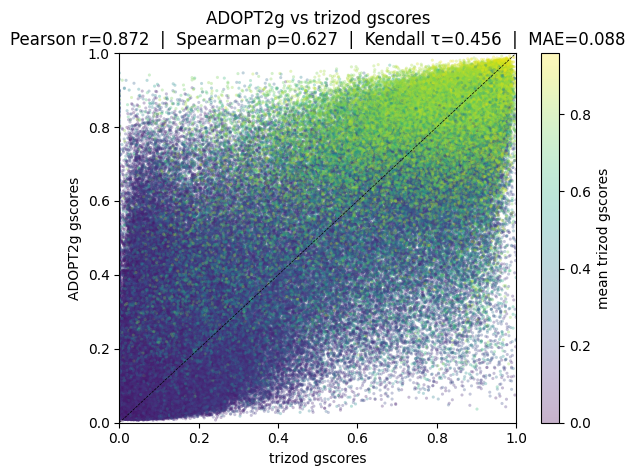

In [4]:
from scipy.stats import kendalltau, pearsonr, spearmanr

mean_trizod_gscores = np.repeat(df_train["gscores"].apply(np.nanmean).values, df_train["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_train["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


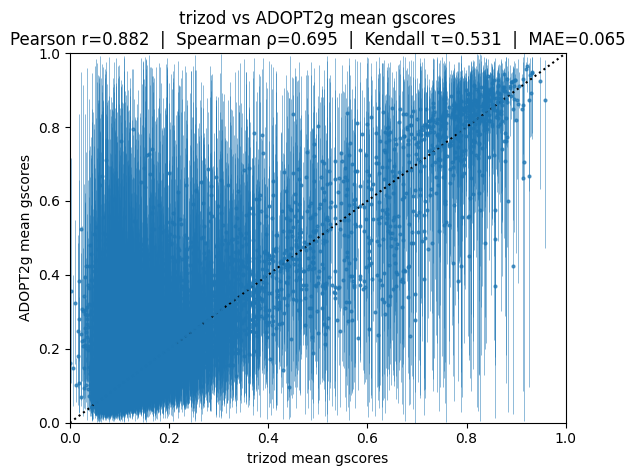

In [5]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_train["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_train["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_train["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_train["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_train["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=[
        df_inferred["mean_gscore"] - df_inferred["mean_gscore_lower"],
        df_inferred["mean_gscore_upper"] - df_inferred["mean_gscore"],
    ],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


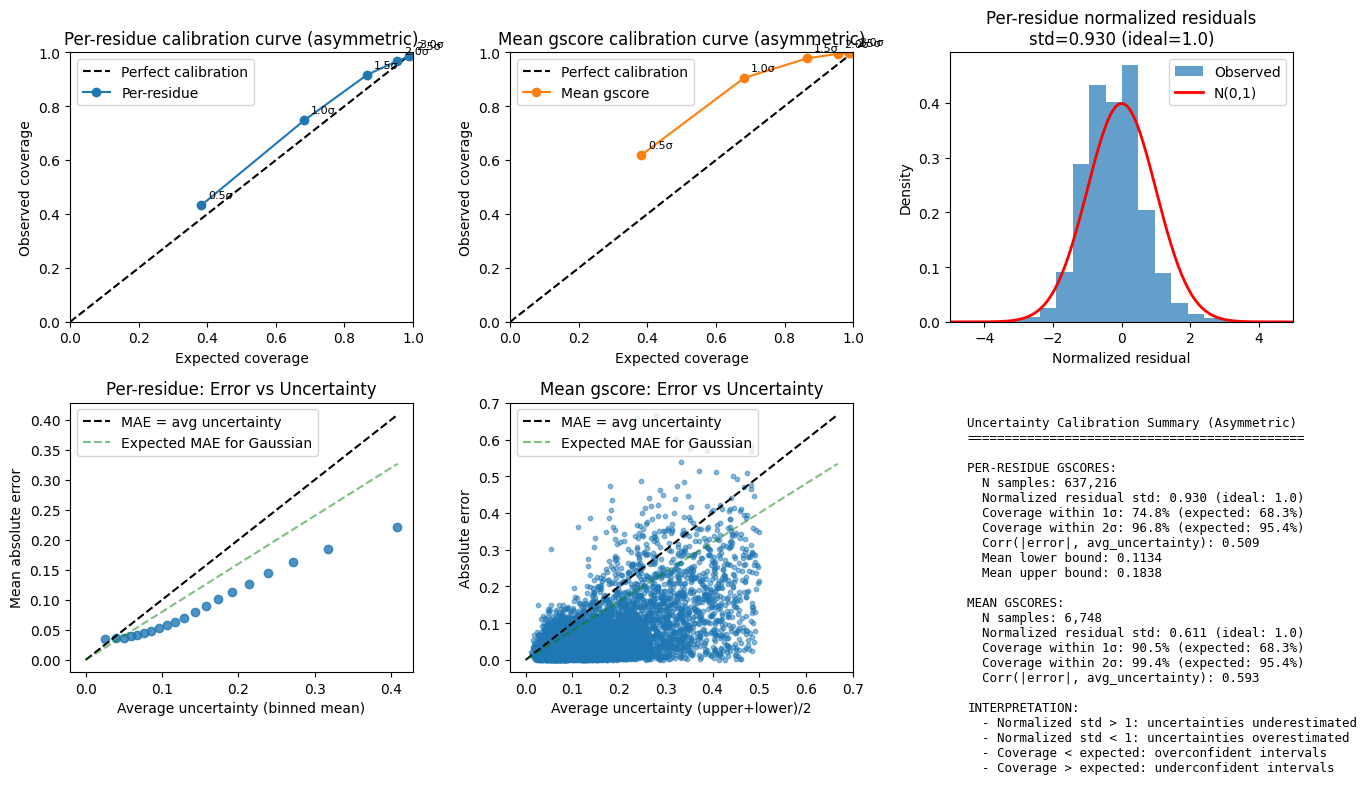

In [6]:
# Uncertainty calibration analysis with asymmetric intervals
# For well-calibrated uncertainties, ~68% of true values should fall within the 1σ interval, ~95% within 2σ

# --- Per-residue uncertainty calibration (asymmetric) ---
trizod_gscores = np.concatenate(df_train["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_lower = np.concatenate(df_inferred["gscores_lower"].values)
pred_gscores_upper = np.concatenate(df_inferred["gscores_upper"].values)

# Compute asymmetric uncertainties (distance from prediction to bounds)
pred_err_lower = pred_gscores - pred_gscores_lower  # positive: how far below pred the lower bound is
pred_err_upper = pred_gscores_upper - pred_gscores  # positive: how far above pred the upper bound is

# Mask for valid values
mask = (
    np.isfinite(trizod_gscores)
    & np.isfinite(pred_gscores)
    & np.isfinite(pred_gscores_lower)
    & np.isfinite(pred_gscores_upper)
    & (pred_err_lower > 0)
    & (pred_err_upper > 0)
)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
err_lower = pred_err_lower[mask]
err_upper = pred_err_upper[mask]

# Compute z-scores using asymmetric bounds
# Use upper bound for positive residuals (true > pred), lower bound for negative residuals
residuals = true_vals - pred_vals
z_scores = np.where(
    residuals >= 0,
    residuals / err_upper,  # true above pred: normalize by upper uncertainty
    residuals / err_lower,  # true below pred: normalize by lower uncertainty (gives negative z)
)

# For binned analysis, use average uncertainty width
avg_err = (err_lower + err_upper) / 2

# Calibration: fraction of points within n-scaled intervals
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])

# For asymmetric intervals: check if true is within [pred - n*err_lower, pred + n*err_upper]
observed_coverage_residue = np.array(
    [np.mean((true_vals >= pred_vals - n * err_lower) & (true_vals <= pred_vals + n * err_upper)) for n in n_sigmas],
)

# --- Mean gscore uncertainty calibration (asymmetric) ---
true_mean = df_train["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_lower = df_inferred["mean_gscore_lower"].values
pred_mean_upper = df_inferred["mean_gscore_upper"].values

# Asymmetric uncertainties for mean
mean_err_lower = pred_mean - pred_mean_lower
mean_err_upper = pred_mean_upper - pred_mean

mask_mean = (
    np.isfinite(true_mean)
    & np.isfinite(pred_mean)
    & np.isfinite(pred_mean_lower)
    & np.isfinite(pred_mean_upper)
    & (mean_err_lower > 0)
    & (mean_err_upper > 0)
)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = np.where(
    residuals_mean >= 0,
    residuals_mean / mean_err_upper[mask_mean],
    residuals_mean / mean_err_lower[mask_mean],
)

observed_coverage_mean = np.array(
    [
        np.mean(
            (true_mean[mask_mean] >= pred_mean[mask_mean] - n * mean_err_lower[mask_mean])
            & (true_mean[mask_mean] <= pred_mean[mask_mean] + n * mean_err_upper[mask_mean]),
        )
        for n in n_sigmas
    ],
)

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue (asymmetric)
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Normalized residual")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue normalized residuals\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted uncertainty - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by average uncertainty
n_bins = 20
err_bins = np.percentile(avg_err, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
for i in range(n_bins):
    in_bin = (avg_err >= err_bins[i]) & (avg_err < err_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(avg_err[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted uncertainty - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
avg_err_mean = (mean_err_lower[mask_mean] + mean_err_upper[mask_mean]) / 2
ax.scatter(avg_err_mean, abs_errors_mean, alpha=0.5, s=10)
max_val = max(avg_err_mean.max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (upper+lower)/2")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary (Asymmetric)
{"=" * 45}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Normalized residual std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors, avg_err)[0, 1]:.3f}
  Mean lower bound: {np.mean(err_lower):.4f}
  Mean upper bound: {np.mean(err_upper):.4f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Normalized residual std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors_mean, avg_err_mean)[0, 1]:.3f}

INTERPRETATION:
  - Normalized std > 1: uncertainties underestimated
  - Normalized std < 1: uncertainties overestimated
  - Coverage < expected: overconfident intervals
  - Coverage > expected: underconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()


In [7]:
all_mean_trizod_gscores = np.repeat(df_train["gscores"].apply(np.nanmean).values, df_train["gscores"].apply(len).values)
all_trizod_gscores = np.concatenate(df_train["gscores"].values)


# def plot_correlations(scores: list[np.ndarray], labels: list[str]) -> None:
#     mask = np.isfinite(scores[0]) & np.isfinite(scores[1])
#     pearson_r, _ = pearsonr(scores[0][mask], scores[1][mask])
#     spearman_rho, _ = spearmanr(scores[0][mask], scores[1][mask])
#     kendall_tau, _ = kendalltau(scores[0][mask], scores[1][mask])
#     mae = np.mean(np.abs(scores[0][mask] - scores[1][mask]))
#     plt.scatter(scores[0], scores[1], alpha=0.3 if mask.sum() > 1000 else 0.8, s=5, lw=0, c=scores[-1])
#     plt.xlabel(labels[0])
#     plt.ylabel(labels[1])
#     plt.title(
#         f"{labels[0]} vs {labels[1]}\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
#     )
#     plt.colorbar(label=labels[-1])
#     if "gscores" in labels[0]:
#         plt.xlim(0, 1)
#     if "gscores" in labels[1]:
#         plt.ylim(0, 1)
#     if ("gscores" in labels[0] and "gscores" in labels[1]) or ("zscores" in labels[0] and "zscores" in labels[1]):
#         plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)
#     plt.show()

from KDEpy import FFTKDE


def plot_correlations(scores: list[np.ndarray], labels: list[str]) -> None:
    x = np.asarray(scores[0])
    y = np.asarray(scores[1])

    mask = np.isfinite(x) & np.isfinite(y)

    pearson_r, _ = pearsonr(x[mask], y[mask])
    spearman_rho, _ = spearmanr(x[mask], y[mask])
    kendall_tau, _ = kendalltau(x[mask], y[mask])
    mae = np.mean(np.abs(x[mask] - y[mask]))

    # --- 2D KDE density ---
    data = np.vstack([x[mask], y[mask]]).T  # shape (n_obs, 2) as in KDEpy examples [web:6]

    # If a 3rd array is provided, treat it as weights (optional, but supported by KDEpy) [web:3]
    weights = None
    cbar_label = "Density"
    if len(scores) >= 3:
        w = np.asarray(scores[-1])
        weights = w[mask]
        cbar_label = f"Weighted density ({labels[-1]})"

    grid_n = 2**8  # grid points per dimension (power of two is typical for FFTKDE examples) [web:6]
    n, d = data.shape
    scott_factor = n ** (-1.0 / (d + 4))  # common KDE scaling for multivariate Scott-type rules [web:2]
    scale = np.mean(np.std(data, axis=0, ddof=1))
    bw = scott_factor * scale
    kde = FFTKDE(bw=bw).fit(data, weights=weights)  # bw='silverman' shown in docs/examples [web:6]
    grid, dens = kde.evaluate((grid_n, grid_n))  # 2D evaluate returns (grid, points) [web:6]

    Xg = grid[:, 0].reshape(grid_n, grid_n)
    Yg = grid[:, 1].reshape(grid_n, grid_n)
    Z = dens.reshape(grid_n, grid_n)

    plt.pcolormesh(Xg, Yg, np.exp(-Z), shading="auto")
    plt.xlabel(labels[0])
    plt.ylabel(labels[1])
    plt.title(
        f"{labels[0]} vs {labels[1]}\n"
        f"Pearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  "
        f"Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}"
    )
    plt.colorbar(label=cbar_label)

    if "gscores" in labels[0]:
        plt.xlim(0, 1)
    if "gscores" in labels[1]:
        plt.ylim(0, 1)
    if ("gscores" in labels[0] and "gscores" in labels[1]) or ("zscores" in labels[0] and "zscores" in labels[1]):
        plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)

    plt.show()

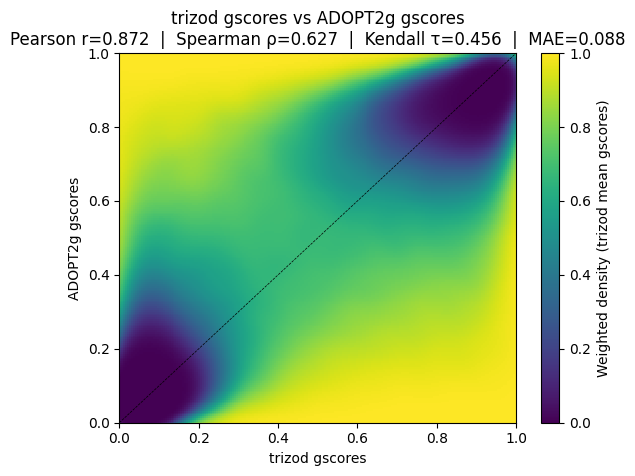

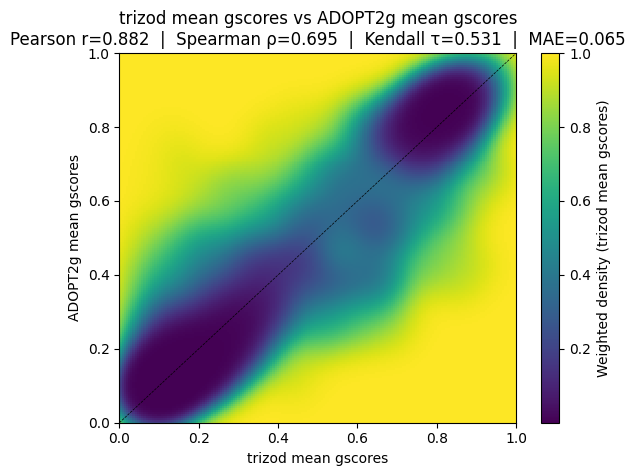

In [8]:
from scipy.special import expit, logit

T = 1
assert df_train.index.equals(df_inferred.index)
plot_correlations(
    [all_trizod_gscores, expit(logit(adopt2_gscores) / T), all_mean_trizod_gscores],
    ["trizod gscores", "ADOPT2g gscores", "trizod mean gscores"],
)
plot_correlations(
    [
        df_train["mean_gscore"],
        # np.array([expit(logit(np.nanmean(df_inferred.loc[i, "gscores"]) / T)) for i in df_train.index]),
        df_inferred["mean_gscore"],
        df_train["mean_gscore"],
    ],
    ["trizod mean gscores", "ADOPT2g mean gscores", "trizod mean gscores"],
)

In [9]:
# from adopt2g.inference import load_ensemble_predictor

# manifest_path = "/home/michele/workdir/ADOPT2g/models/seed887_n7/manifest.json"
# predictor = load_ensemble_predictor(manifest_path, use_calibration=False)
# temperature_scaling_factor, uncertainty_calibration_factor = predictor.compute_calibration_factors(
#     sequences=df_train["sequence"].tolist(),
#     gscores=df_train["gscores"].tolist(),
# )
# temperature_scaling_factor, uncertainty_calibration_factor